In [1]:
import os
import json
from joblib import load
from typing import Callable,Tuple,Dict,Any

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

import shap
from IPython.display import display,HTML

from constants import OUTPUTS_PATH, PLOTS_PATH, OURS_COLUMNS, RAW_COLUMNS, CAIDE_COLUMNS

/home/alexandre/projects/mestrado-aulas/mineracao-de-dados/trabalho/projeto/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df_metrics_test = pd.DataFrame(columns=('dataset_type', 'columns', 'params_type', 'metric', 'value', 'model'))

row_i = 0
for dataset_type in os.listdir(OUTPUTS_PATH):
    for params_type in os.listdir(os.path.join(OUTPUTS_PATH, dataset_type)):
        for columns in os.listdir(os.path.join(OUTPUTS_PATH, dataset_type, params_type)):
            for model in os.listdir(os.path.join(OUTPUTS_PATH, dataset_type, params_type, columns)):
                
                if 'npy' in model:
                    continue

                metrics_file = os.path.join(
                    OUTPUTS_PATH, dataset_type, params_type, columns, model, 'output_test_metrics.json'
                )

                with open(metrics_file, 'r') as file:
                    json_data = json.load(file)

                    for k in json_data.keys():
                        if ('confusion_matrix' == k) or \
                            ('macro' in k) or \
                            ('micro' in k) or \
                            ('jaccard' in k):
                            continue
                        df_metrics_test.loc[row_i] = {
                            'dataset_type': dataset_type,
                            'columns':columns,
                            'params_type':params_type,
                            'metric': k,
                            'value': json_data[k],
                            'model':model
                        }

                        row_i += 1
df_metrics_test = df_metrics_test.sort_values(by='model')
df_metrics_test.head()


,dataset_type,columns,params_type,metric,value,model
402,not_augmented,CAIDE,best-params,precision,0.737288,bagging_logistic
544,augmented,raw,default,roc_auc,0.840575,bagging_logistic
121,not_augmented,raw,default,f1,0.714286,bagging_logistic
120,not_augmented,raw,default,accuracy,0.802326,bagging_logistic
332,not_augmented,raw,best-params,precision,0.735043,bagging_logistic


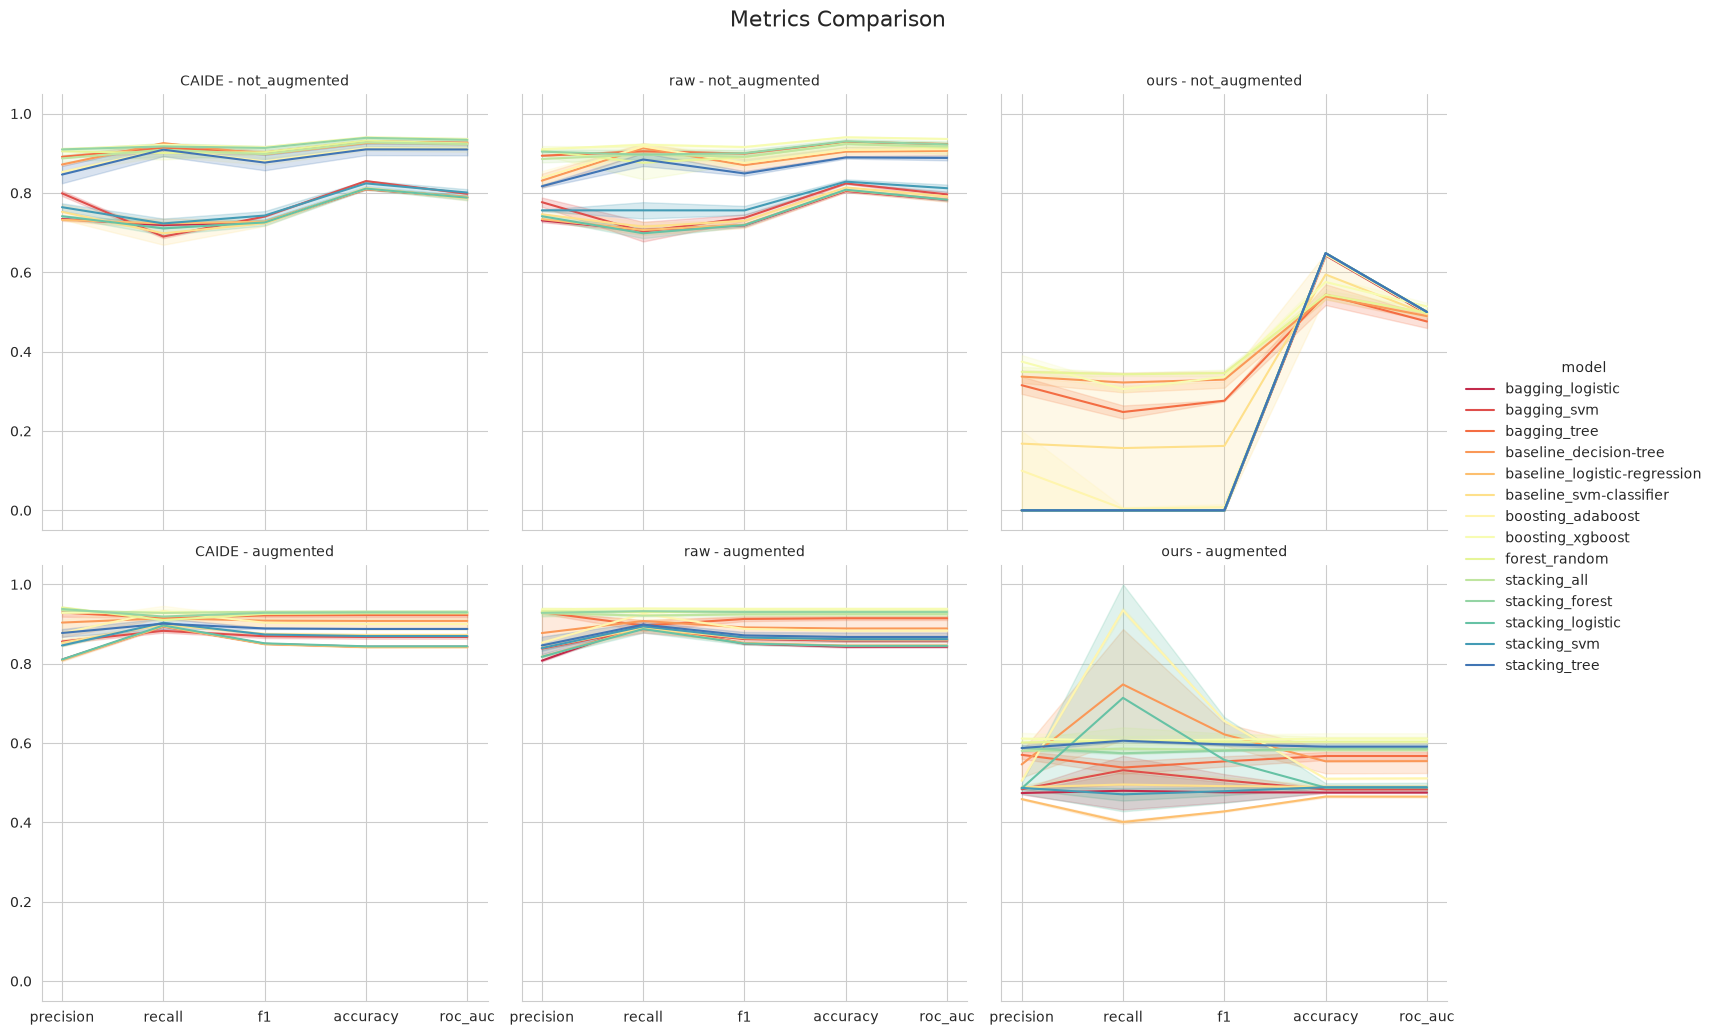

In [3]:
sns.set_style("whitegrid")
g = sns.relplot(
    kind='line',
    data=df_metrics_test,
    x='metric',
    y='value',
    hue='model',
    row='dataset_type',
    col='columns',
    palette='Spectral'
)
g.set_titles(template="{col_name} - {row_name}")
g.set_axis_labels("", "")
plt.suptitle('Metrics Comparison', y=1.05, fontsize=16)
plt.savefig(PLOTS_PATH('comparison_metrics_per_model.png'), dpi=300, bbox_inches='tight')
plt.show()

dataset_type       not_augmented
columns                      raw
params_type          best-params
metric                        f1
value                   0.918033
model           boosting_xgboost
Name: 336, dtype: object
dataset_type    not_augmented
columns                  ours
params_type           default
metric                     f1
value                 0.35443
model           forest_random
Name: 21, dtype: object
dataset_type           augmented
columns                      raw
params_type          best-params
metric                        f1
value                   0.941441
model           boosting_xgboost
Name: 756, dtype: object
dataset_type            augmented
columns                      ours
params_type               default
metric                         f1
value                    0.665667
model           stacking_logistic
Name: 461, dtype: object


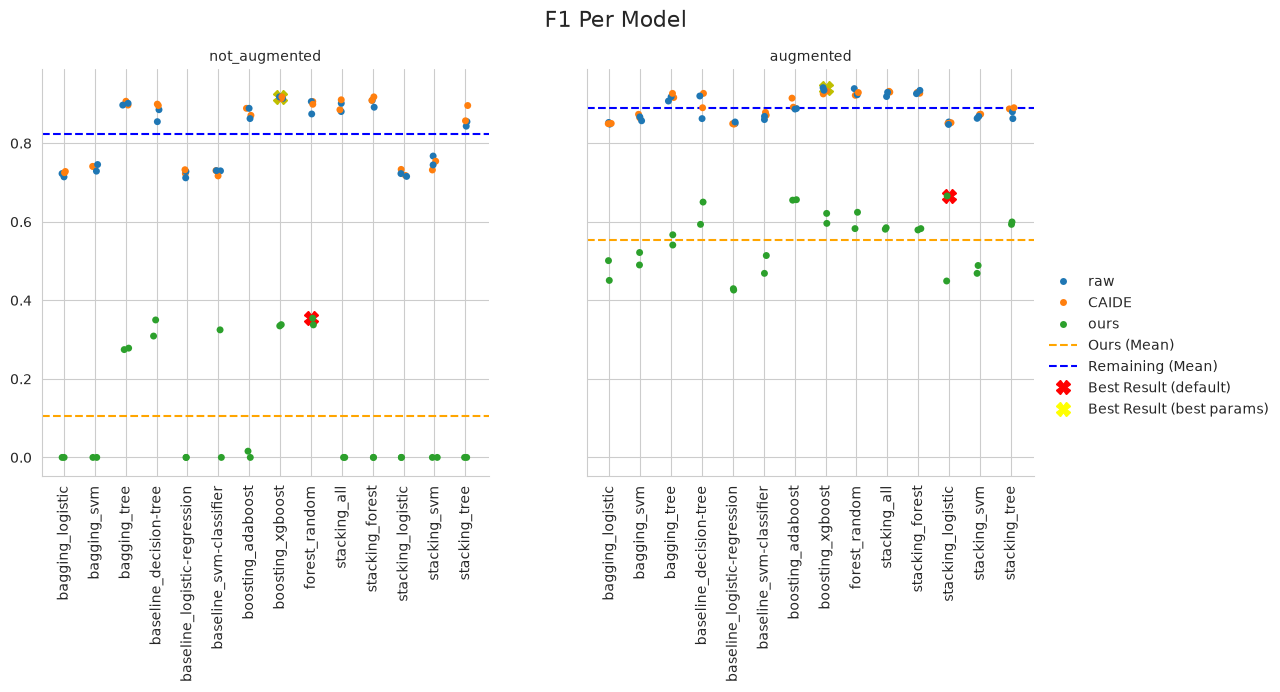

In [4]:
sns.set_style("whitegrid")
f1_data = df_metrics_test.loc[(df_metrics_test['metric'] == 'f1')]

not_augmented_not_ours = f1_data[(f1_data['dataset_type'] == 'not_augmented')&(f1_data['columns'] != 'ours')]
not_augmented_not_ours_best_value = not_augmented_not_ours['value'].idxmax()

augmented_not_ours = f1_data[(f1_data['dataset_type'] == 'augmented')&(f1_data['columns'] != 'ours')]
augmented_not_ours_best_value = augmented_not_ours['value'].idxmax()

not_augmented_ours = f1_data[(f1_data['dataset_type'] == 'not_augmented')&(f1_data['columns'] == 'ours')]
not_augmented_ours_best_value = not_augmented_ours['value'].idxmax()

augmented_ours = f1_data[(f1_data['dataset_type'] == 'augmented')&(f1_data['columns'] == 'ours')]
augmented_ours_best_value = augmented_ours['value'].idxmax()

g = sns.catplot(
    kind="strip", 
    data=f1_data, 
    x="model", 
    y='value',
    col='dataset_type',
    hue='columns',
)

for ax in g.axes.flat:
  ax.grid(
      True, axis="x",
  ) 

print(not_augmented_not_ours.loc[not_augmented_not_ours_best_value])
print(not_augmented_ours.loc[not_augmented_ours_best_value])

print(augmented_not_ours.loc[augmented_not_ours_best_value])
print(augmented_ours.loc[augmented_ours_best_value])

not_agumented_ax = g.axes[0,0]
agumented_ax = g.axes[0,1]

not_agumented_ax.plot(
    not_augmented_not_ours.loc[not_augmented_not_ours_best_value]['model'], 
    not_augmented_not_ours.loc[not_augmented_not_ours_best_value]['value'], 
    'rX' if not_augmented_not_ours.loc[not_augmented_not_ours_best_value]['params_type'] == 'default' else 'yX',
    markersize=10)

not_agumented_ax.plot(
    not_augmented_ours.loc[not_augmented_ours_best_value]['model'], 
    not_augmented_ours.loc[not_augmented_ours_best_value]['value'], 
    'rX' if not_augmented_ours.loc[not_augmented_ours_best_value]['params_type'] == 'default' else 'yX',
    markersize=10)

agumented_ax.plot(
    augmented_not_ours.loc[augmented_not_ours_best_value]['model'], 
    augmented_not_ours.loc[augmented_not_ours_best_value]['value'], 
    'rX' if augmented_not_ours.loc[augmented_not_ours_best_value]['params_type'] == 'default' else 'yX',
    markersize=10)

agumented_ax.plot(
    augmented_ours.loc[augmented_ours_best_value]['model'], 
    augmented_ours.loc[augmented_ours_best_value]['value'], 
    'rX' if augmented_ours.loc[augmented_ours_best_value]['params_type'] == 'default' else 'yX',
    markersize=10)


not_agumented_ax.axhline(
    y=f1_data.loc[(f1_data['dataset_type'] == 'not_augmented')&(f1_data['columns'] != 'ours')]['value'].mean(),
    linestyle='--', 
    color='blue',
)

not_agumented_ax.axhline(
    y=f1_data.loc[(f1_data['dataset_type'] == 'not_augmented')&(f1_data['columns'] == 'ours')]['value'].mean(),
    linestyle='--', 
    color='orange',
)

agumented_ax.axhline(
    y=f1_data.loc[(f1_data['dataset_type'] == 'augmented')&(f1_data['columns'] != 'ours')]['value'].mean(),
    linestyle='--', 
    color='blue',
)

agumented_ax.axhline(
    y=f1_data.loc[(f1_data['dataset_type'] == 'augmented')&(f1_data['columns'] == 'ours')]['value'].mean(),
    linestyle='--', 
    color='orange',
)

g.set_xticklabels(rotation=90)
g.set_axis_labels('', '')
g.set_titles(template="{col_name}")

ours = plt.Line2D([], [], color='orange', linestyle='--')
not_ours = plt.Line2D([], [], color='blue', linestyle='--')
best_default = plt.Line2D([],[], color='red', marker="X", linestyle='None', markersize=10)
best_params = plt.Line2D([],[], color='yellow', marker="X", linestyle='None', markersize=10)

g._legend_data['Ours (Mean)'] = ours
g._legend_data['Remaining (Mean)'] = not_ours
g._legend_data['Best Result (default)'] = best_default
g._legend_data['Best Result (best params)'] = best_params
g._legend.remove()
g.add_legend()

plt.suptitle('F1 Per Model', y=1.05, fontsize=16)
plt.savefig(PLOTS_PATH('f1_per_model.png'), dpi=300, bbox_inches='tight')
plt.show()

In [5]:
def xgboost_parser(model:str) -> Dict[str,Any]:
    with open(model, "rb") as f:
        clf = load(f)
        return {
            'eta': clf.get_params()['eta'],
            'gamma': clf.gamma,
            'max_depth': clf.max_depth
        }

def forest_parser(model:str) -> Dict[str,Any]:
    with open(model, "rb") as f:
        clf = load(f)

        return {
            'criterion': clf.criterion,
            'min_samples_split': clf.min_samples_split,
            'max_depth': clf.max_depth,
            'max_features': clf.max_features
        }

def stacking_log_parser(model:str) -> Dict[str,Any]:
    with open(model, "rb") as f:
        clf = load(f)

        return {
            'stack_method': clf.stack_method,
        }


In [6]:
def get_best_params_for_model(path:str, parser:Callable) -> Tuple[Dict[str,Any], Dict[str,Any]]:
    output_search = os.path.join(path, 'grid_search_output.csv')
    output_metrics = os.path.join(path, 'output_test_metrics.json')
    model = os.path.join(path, 'model.pkl')

    cv_output = pd.read_csv(output_search)

    cv_params = parser(model)

    query = ' and '.join([
            f'param_{k.strip()} == {float(v)}' 
                if float('nan') != v and v is not None
                else f'(param_{k.strip()}.isna() or param_{k.strip()}.isnull())' 
            for k,v in cv_params.items()
        ])
    cv_portion = cv_output.query(query)

    assert len(cv_portion) > 0, f"Failed on get dataframe: {path}\nquery: {query}\ncv metrics: {cv_metrics_data}"


    metrics = {}

    for step in ['train', 'test']:
        for metric in ['precision', 'recall', 'f1']:
            k = f'mean_{step}_{metric}'
            v = cv_portion[k].item()
            metrics[k] = v

    with open(output_metrics, 'r') as file:
        j_file = json.load(file)
        for metric in ['precision', 'recall', 'f1']:
            metrics[f'eval_{metric}'] = j_file[metric]

    return cv_params, metrics

In [7]:
data = {}

table = """
<table>
    <caption>XGBoost best params outcomes</caption>
    <thead>
        <tr>
            <th>dataset</th>
            <th>columns</th>
            <th>params</th>
            
            <th>mean_train_recall</th>
            <th>mean_train_f1</th>
            <th>mean_train_precision</th>
            
            <th>mean_test_recall</th>
            <th>mean_test_f1</th>
            <th>mean_test_precision</th>

            <th>eval_recall</th>
            <th>eval_f1</th>
            <th>eval_precision</th>
        </tr>
    </thead>
    <tbody>
"""

for i,dataset_type in enumerate(os.listdir(OUTPUTS_PATH)):
    data[dataset_type] = {}
    
    for j,columns in enumerate(['ours', 'CAIDE', 'raw']):
        path = os.path.join(OUTPUTS_PATH, dataset_type, 'best-params', columns, 'boosting_xgboost')

        params, metrics = get_best_params_for_model(path, xgboost_parser)
        
        data[dataset_type][columns] = {
            "params": params,
            "metrics":metrics
        }

        table += f"""
            <tr>
                <td>{dataset_type}</td>
                <td>{columns}</td>
                <td>{json.dumps(params)}</td>

                <td>{metrics['mean_train_recall']}</td>
                <td>{metrics['mean_train_f1']}</td>
                <td>{metrics['mean_train_precision']}</td>
                
                <td>{metrics['mean_test_recall']}</td>
                <td>{metrics['mean_test_f1']}</td>
                <td>{metrics['mean_test_precision']}</td>
    
                <td>{metrics['eval_recall']}</td>
                <td>{metrics['eval_f1']}</td>
                <td>{metrics['eval_precision']}</td>
            </tr>
        """
        
table += "</tbody></table>"
        
display(HTML(table))

dataset,columns,params,mean_train_recall,mean_train_f1,mean_train_precision,mean_test_recall,mean_test_f1,mean_test_precision,eval_recall,eval_f1,eval_precision
not_augmented,ours,"{""eta"": 0.7, ""gamma"": 0, ""max_depth"": 6}",0.8235351019001935,0.8672651892813509,0.9167617622201588,0.3004628655585946,0.3212657004830918,0.3482839193913217,0.3140495867768595,0.33480176211453744,0.3584905660377358
not_augmented,CAIDE,"{""eta"": 0.1, ""gamma"": 0, ""max_depth"": 2}",0.9248986298465536,0.9420902207698733,0.9599727584895442,0.9177361666316012,0.9329866489759684,0.9492335743628406,0.9256198347107438,0.9180327868852459,0.9105691056910569
not_augmented,raw,"{""eta"": 0.1, ""gamma"": 0, ""max_depth"": 2}",0.9254140937640792,0.942368675370234,0.9600009911535542,0.9177151272880288,0.9339682405139342,0.9512607719028692,0.9256198347107438,0.9180327868852459,0.9105691056910569
augmented,ours,"{""eta"": 0.7, ""gamma"": 0, ""max_depth"": 6}",0.9143258426966292,0.9113731372151824,0.9085367464744872,0.6269662921348316,0.6140746238477087,0.6027768036729564,0.6171171171171171,0.6213151927437641,0.6255707762557078
augmented,CAIDE,"{""eta"": 0.5, ""gamma"": 0, ""max_depth"": 6}",1.0,1.0,1.0,0.901123595505618,0.9248206045075716,0.9502521594623364,0.9369369369369369,0.9327354260089686,0.9285714285714286
augmented,raw,"{""eta"": 0.1, ""gamma"": 0.5, ""max_depth"": 5}",0.9983146067415728,0.9977543854119754,0.9971953415685576,0.897752808988764,0.9274437154564876,0.959317974019909,0.9414414414414415,0.9414414414414415,0.9414414414414415


In [23]:
def confusion_matrix_plot(model:str):
    fig,ax = plt.subplots(2,3, figsize=(15,10))
    
    for i,dataset in enumerate(['default', 'best-params']):
        for j,column in enumerate(['ours', 'CAIDE', 'raw']):
            path_data = os.path.join(OUTPUTS_PATH, 'augmented', dataset, column, model, 'output_test_metrics.json')
            
            with open(path_data, 'r') as file:
                cm = json.load(file)['confusion_matrix']
            
            sns.heatmap(cm, annot=True, fmt='.0f', ax=ax[i,j], cbar=False)
            ax[i,j].set_title(f'{dataset} - {column}')
            ax[i,j].set_xticklabels([])
            ax[i,j].set_yticklabels([])
            
    fig.suptitle(f'Confusion Matrix - {model}')
    fig.savefig(PLOTS_PATH(f'confusion_matrix_{model}.png'), dpi=300, bbox_inches='tight')
    plt.show()

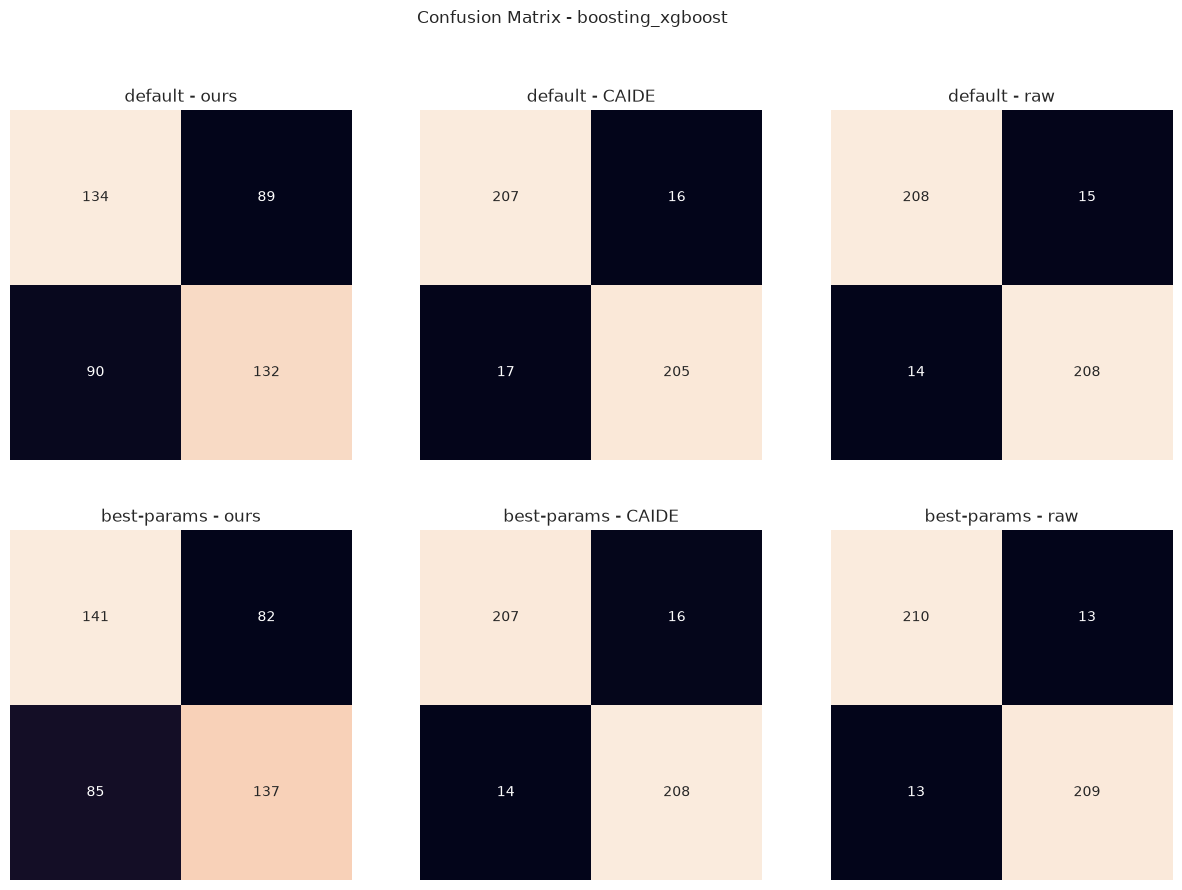

In [24]:
confusion_matrix_plot('boosting_xgboost')

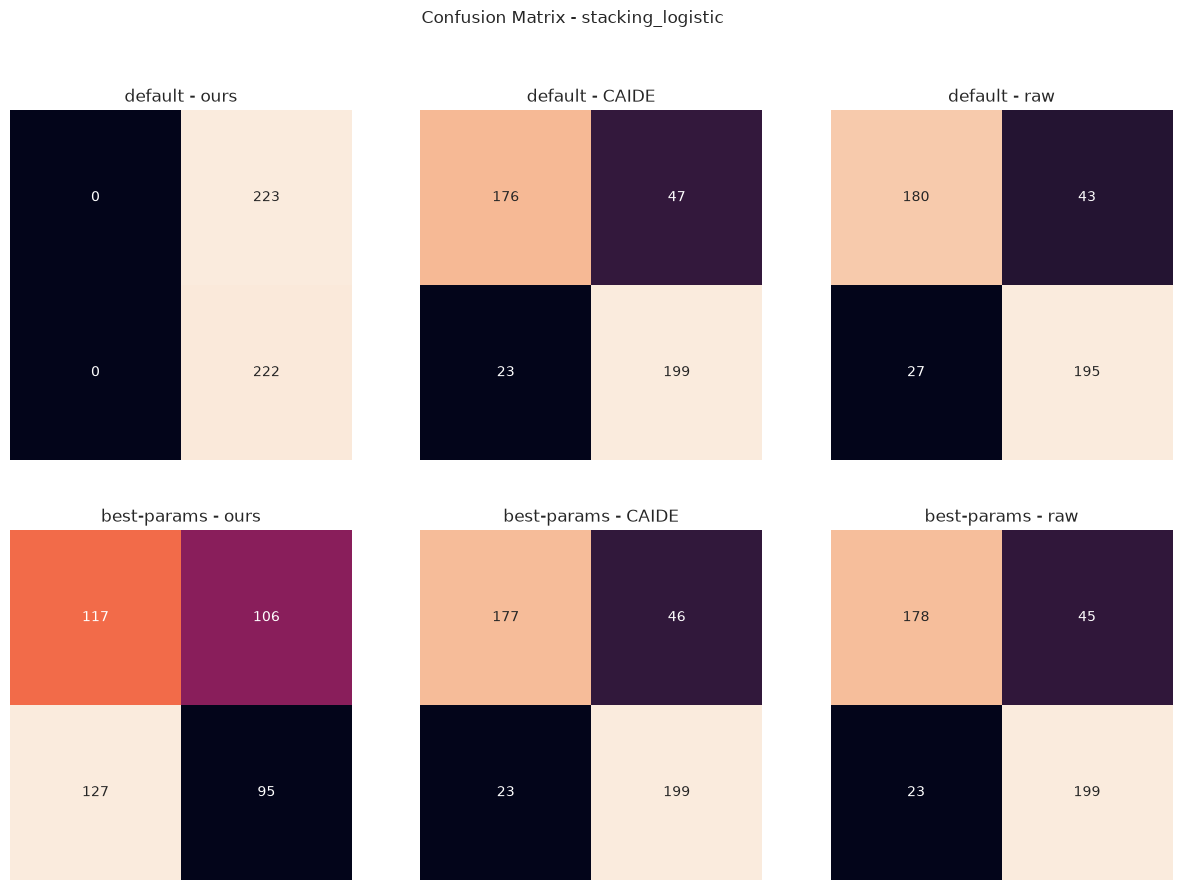

In [25]:
confusion_matrix_plot('stacking_logistic')

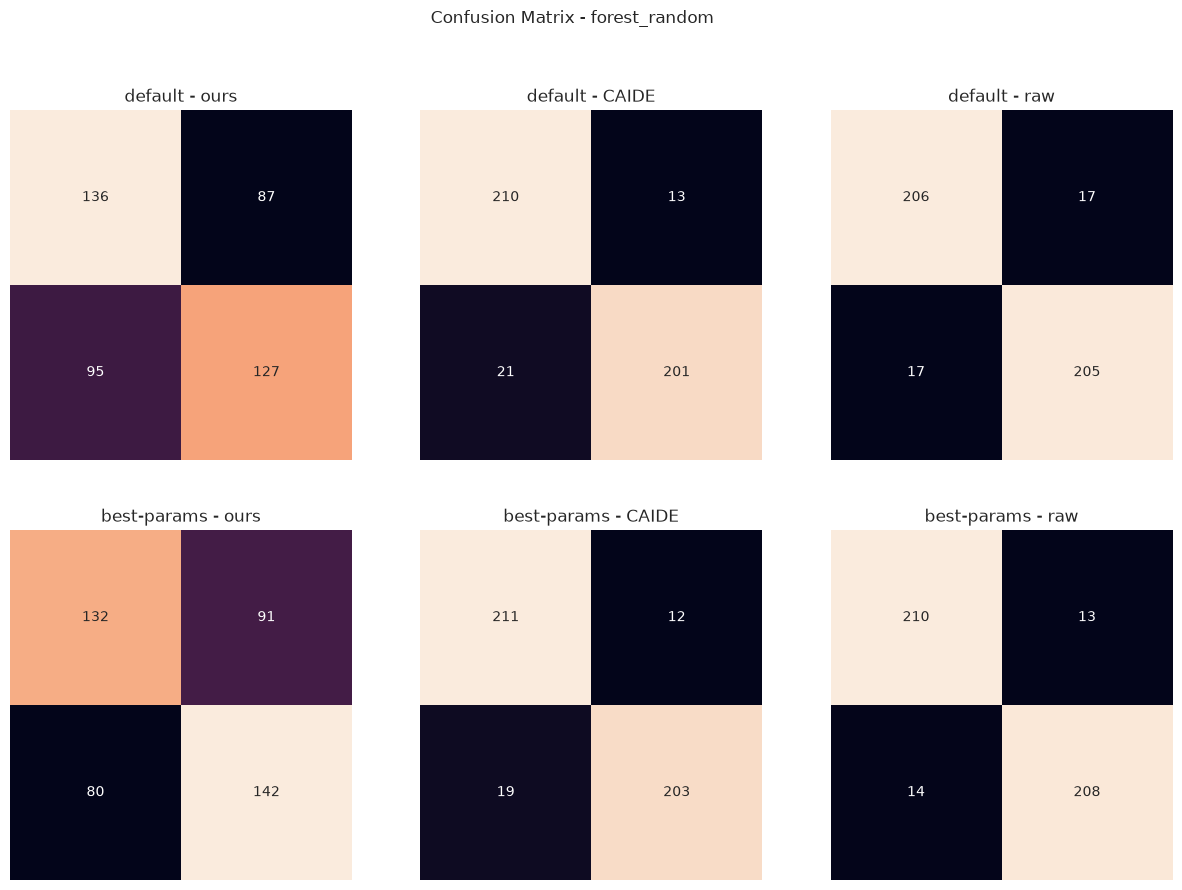

In [26]:
confusion_matrix_plot('forest_random')